In [1]:
from pathlib import Path

from IPython.display import Image, display
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
from mpi4py import MPI
from dolfinx import plot as dolfinx_plot
from dolfinx.io import gmsh as dolfinx_gmsh

from src.config import Geometry
from src.mesh import MagnetronMesh, MeshSettings
from src.magnetostatics import MagnetostaticSettings, MagnetostaticSimulation
from src.visualization import (
    plot_magnetic_field,
    plot_target_surface_profile,
)

In [2]:
RESULTS_DIR = Path("results/experiment2")

geometry = Geometry(
    target_diameter=50.8,
    target_thickness=3.0,
    magnet_height=10.0,
    inner_magnet_diameter=15.0,
    outer_magnet_diameter=8.0,
    outer_magnet_ring_radius=18.0,
    magnet_to_target_distance=5.0,
)

mesh_settings = MeshSettings(
    min_size=0.025,
    max_size=0.5,
)

physics_settings = MagnetostaticSettings(
    remanence=2,
    relative_permeability_air=1.0,
    relative_permeability_target=1.0,
    relative_permeability_magnet=1.05,
    relative_permeability_backing_plate=1.0,
)


Info    : Meshing 1D...nts - Adding holes                                                                                              
Info    : [  0%] Meshing curve 15 (Line)
Info    : [ 10%] Meshing curve 19 (Line)
Info    : [ 10%] Meshing curve 23 (Line)
Info    : [ 20%] Meshing curve 24 (Line)
Info    : [ 20%] Meshing curve 25 (Line)
Info    : [ 20%] Meshing curve 26 (Line)
Info    : [ 30%] Meshing curve 27 (Line)
Info    : [ 30%] Meshing curve 28 (Line)
Info    : [ 40%] Meshing curve 29 (Line)
Info    : [ 40%] Meshing curve 30 (Line)
Info    : [ 40%] Meshing curve 31 (Line)
Info    : [ 50%] Meshing curve 32 (Line)
Info    : [ 50%] Meshing curve 33 (Line)
Info    : [ 60%] Meshing curve 34 (Line)
Info    : [ 60%] Meshing curve 35 (Line)
Info    : [ 60%] Meshing curve 36 (Line)
Info    : [ 70%] Meshing curve 37 (Line)
Info    : [ 70%] Meshing curve 38 (Line)
Info    : [ 70%] Meshing curve 39 (Line)
Info    : [ 80%] Meshing curve 40 (Line)
Info    : [ 80%] Meshing curve 41 (Line)
Inf

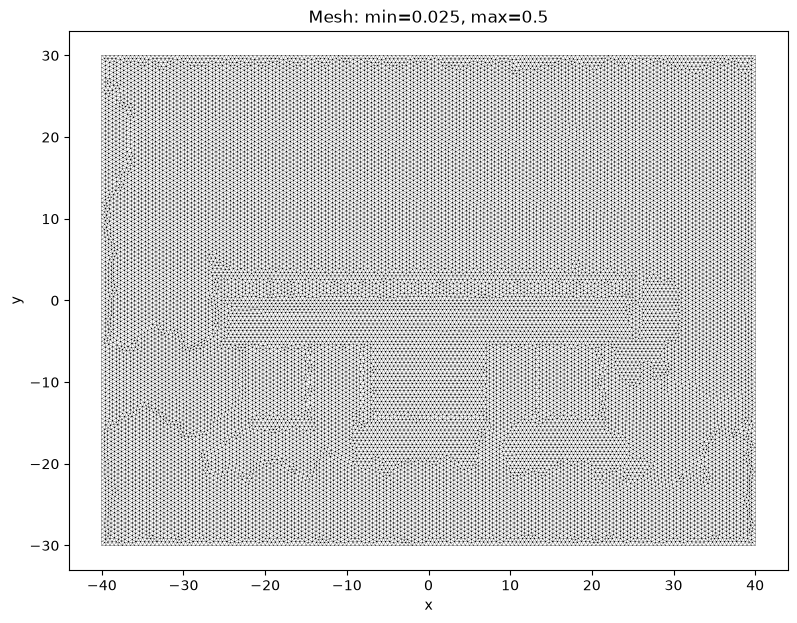

In [3]:
if MPI.COMM_WORLD.size != 1:
    raise RuntimeError("This interactive notebook requires one MPI process.")

mesh_path = MagnetronMesh(geometry, mesh_settings).generate(
    RESULTS_DIR / "mesh.msh"
)

mesh_data = dolfinx_gmsh.read_from_msh(str(mesh_path), MPI.COMM_WORLD, gdim=2)
cells, _, points = dolfinx_plot.vtk_mesh(mesh_data.mesh)
triangles = cells.reshape(-1, 4)[:, 1:]
triangulation = mtri.Triangulation(points[:, 0], points[:, 1], triangles)

figure, axis = plt.subplots(figsize=(12, 7))
axis.triplot(triangulation, color="black", linewidth=0.2)
axis.set_aspect("equal")
axis.set_xlabel("x")
axis.set_ylabel("y")
axis.set_title(f"Mesh: min={mesh_settings.min_size}, max={mesh_settings.max_size}")
plt.show()


Info    : Reading 'results/experiment2/mesh.msh'...
Info    : 54 entities
Info    : 22897 nodes
Info    : 45232 elements
Info    : Done reading 'results/experiment2/mesh.msh'
Field data: results/experiment2/fields.xdmf
Metadata: results/experiment2/simulation.json


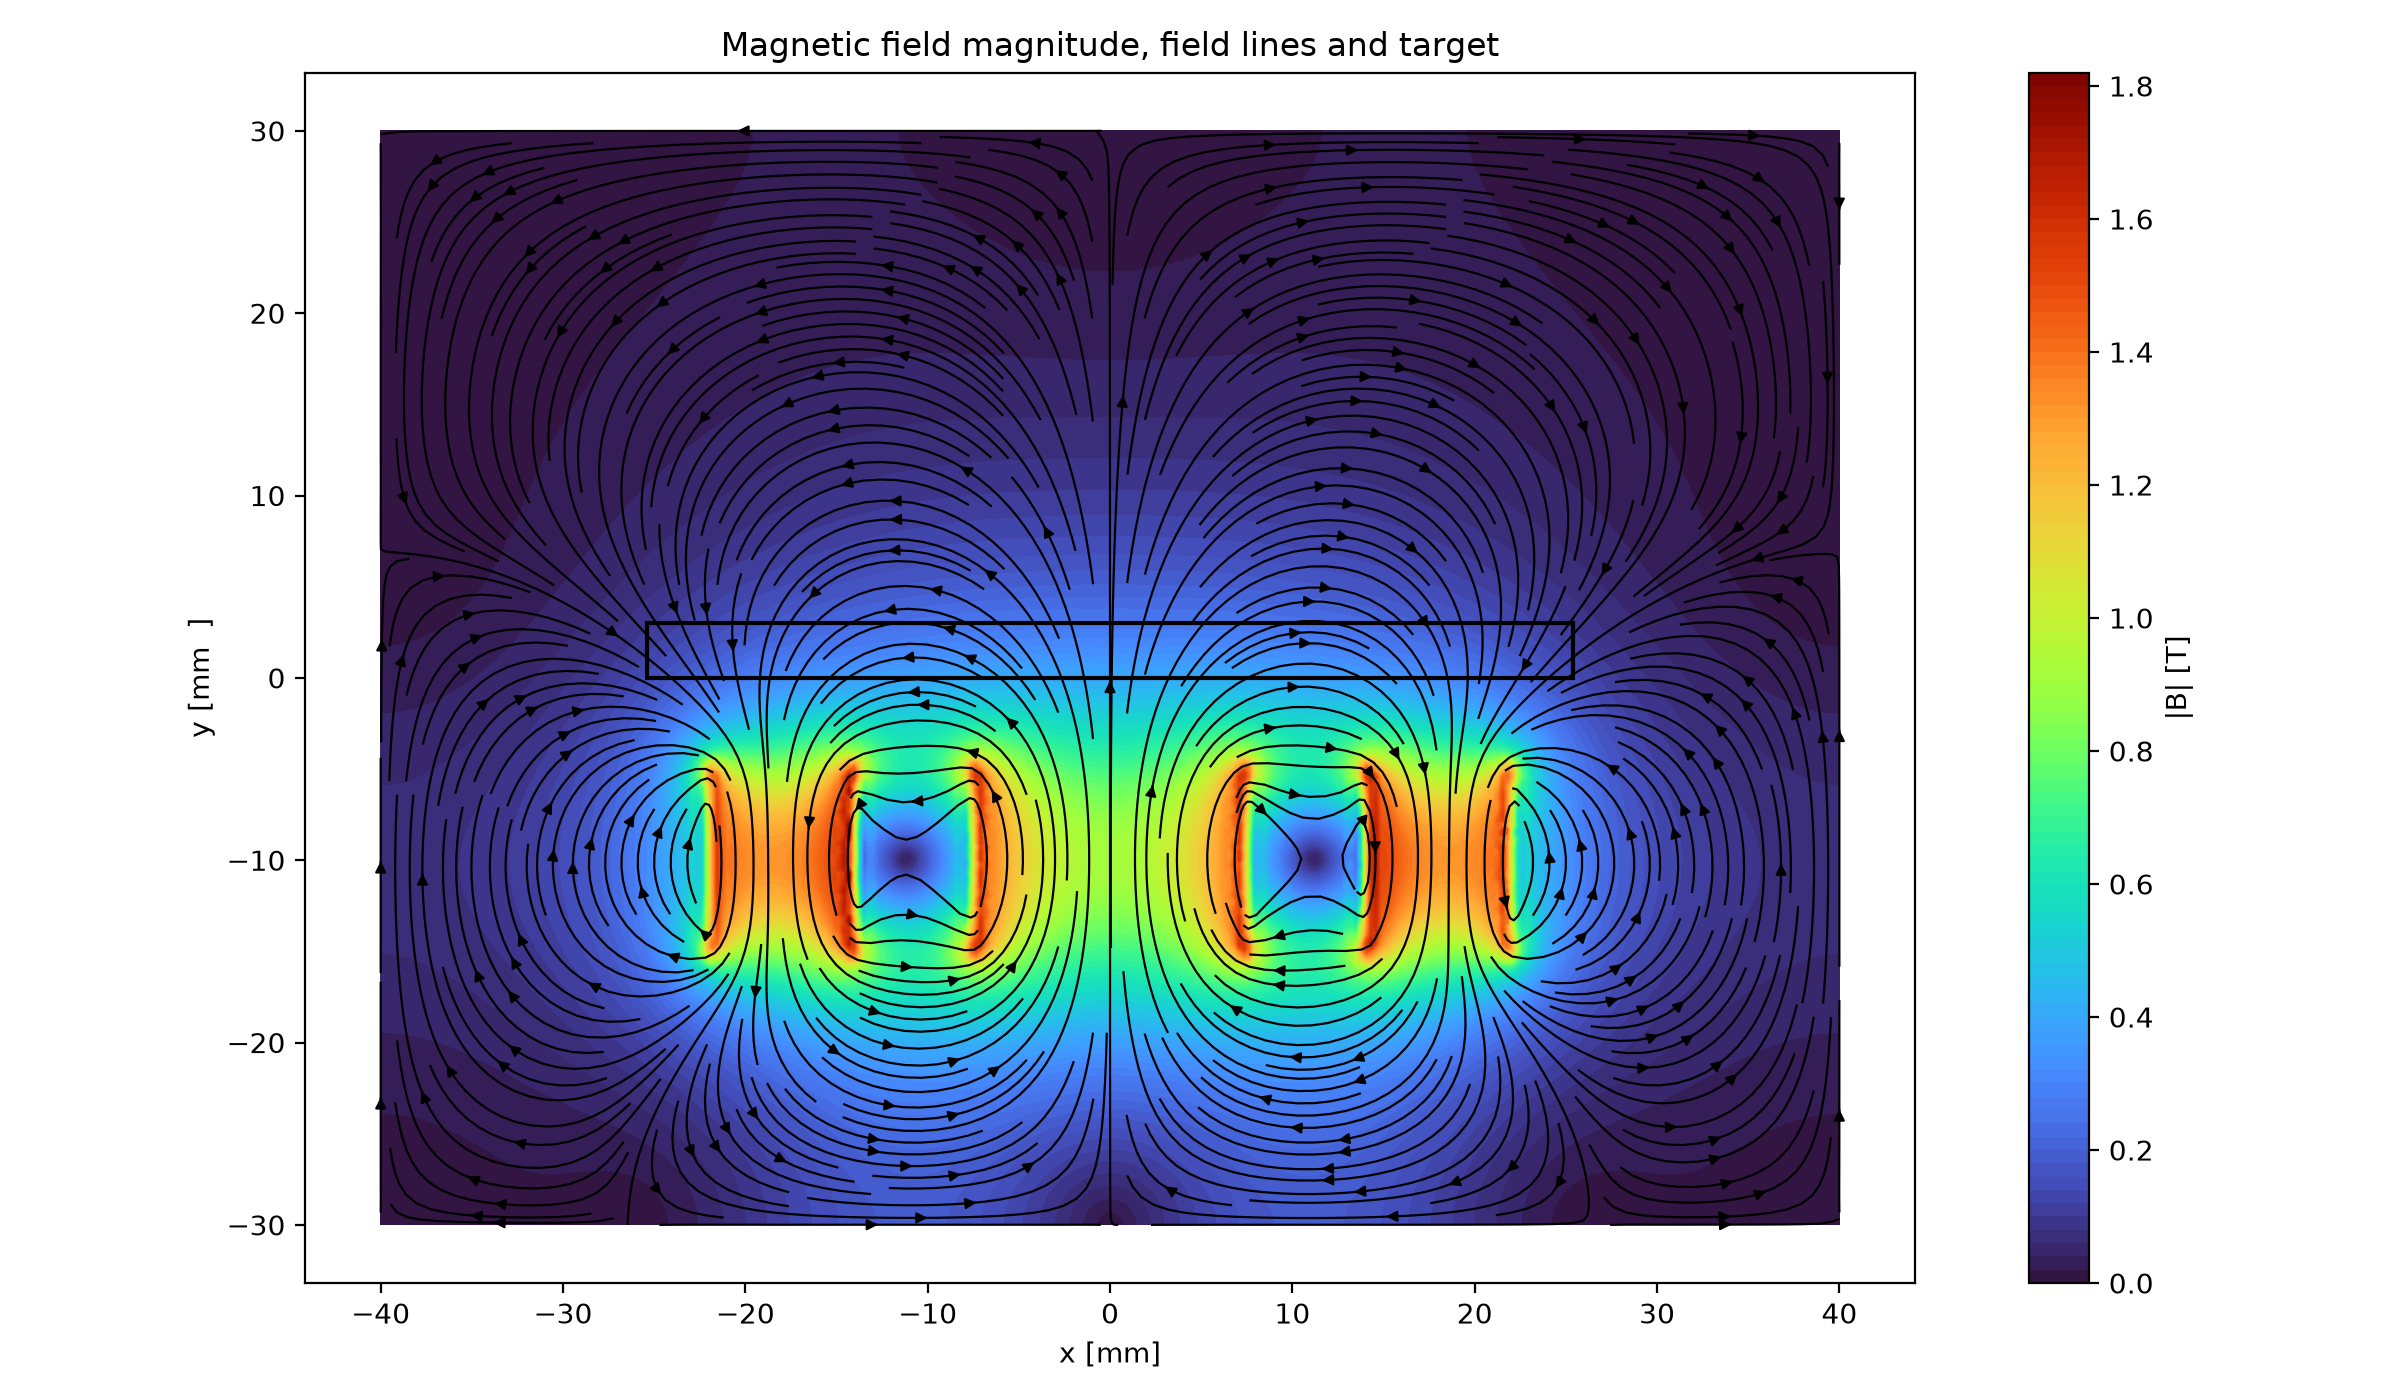

In [5]:
result = MagnetostaticSimulation(mesh_path, physics_settings).solve(RESULTS_DIR)
field_plot_path = plot_magnetic_field(
    result,
    RESULTS_DIR / "field.png",
    target_diameter=geometry.target_diameter,
    target_thickness=geometry.target_thickness,
)

print(f"Field data: {result.fields_file}")
print(f"Metadata: {result.metadata_file}")
display(Image(filename=str(field_plot_path)))


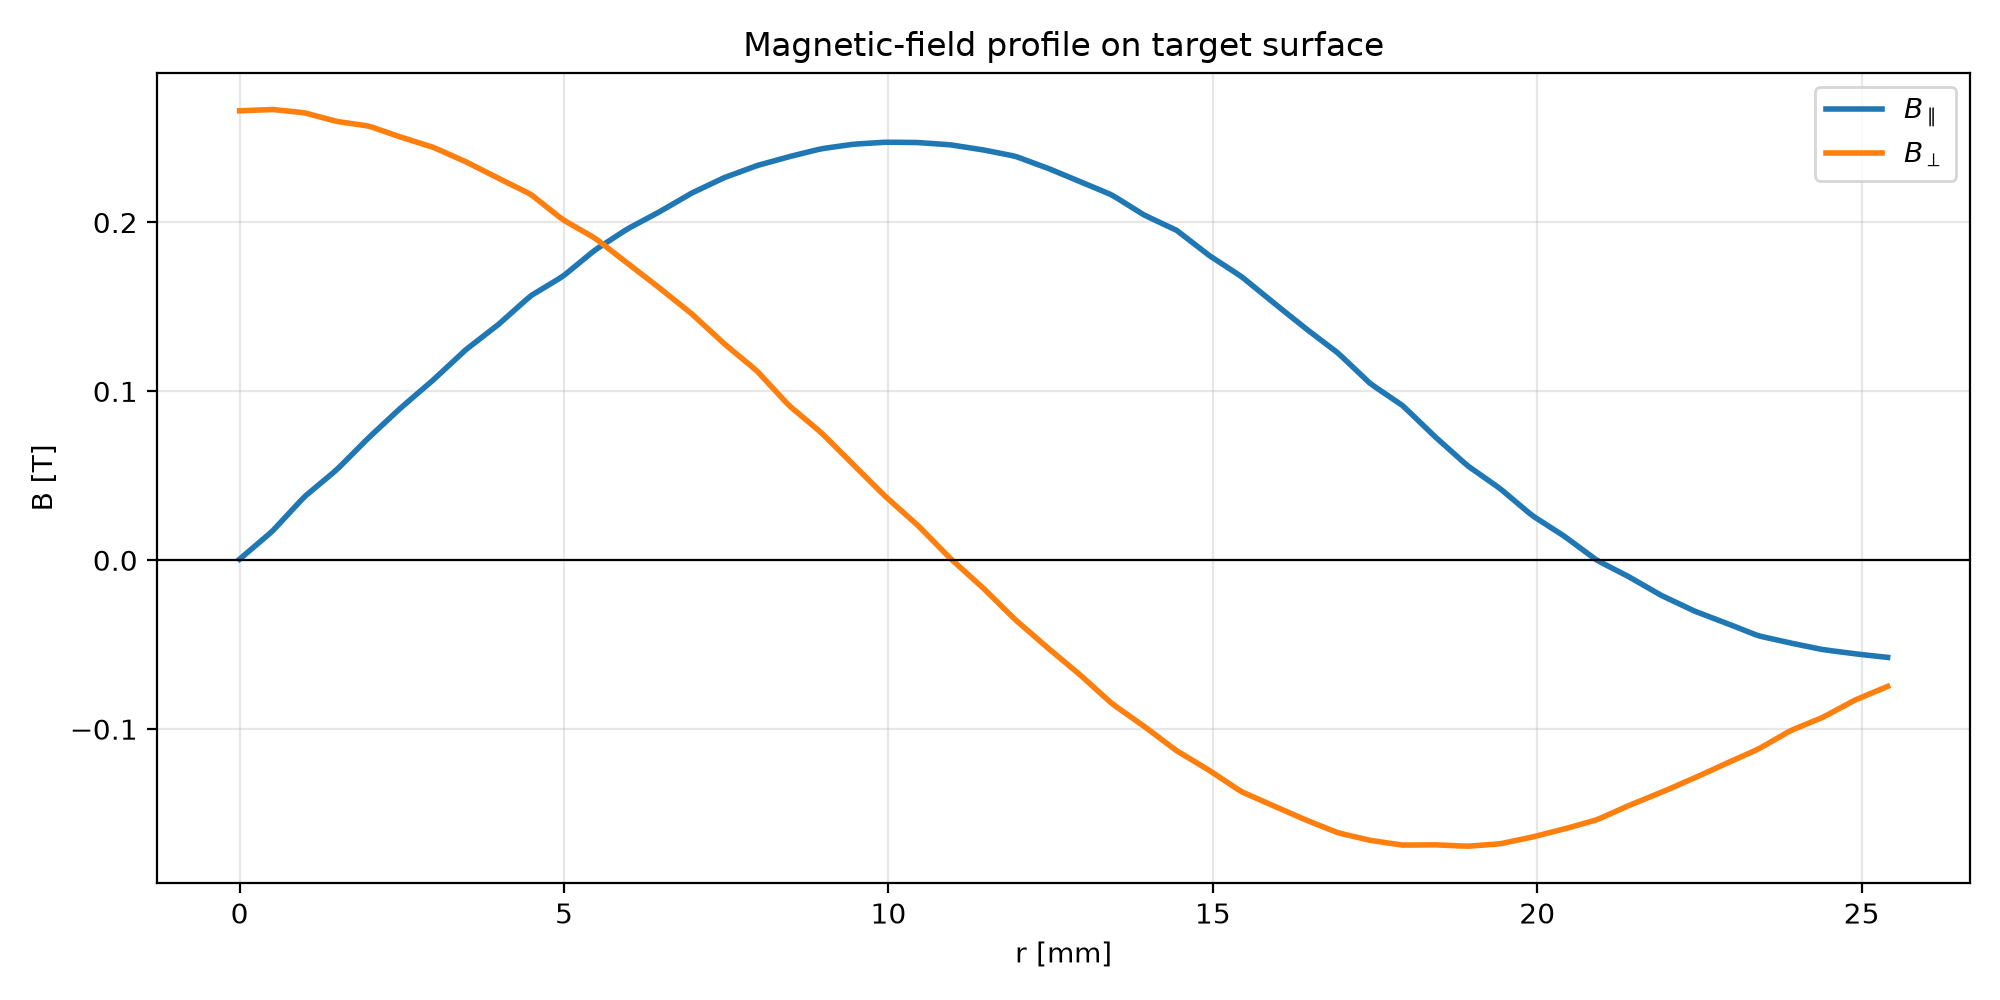

Profile data: results/experiment2/target_surface_profile.csv


In [6]:
profile_plot_path = RESULTS_DIR / "target_surface_profile.png"
radius, b_parallel, b_perpendicular = plot_target_surface_profile(
    result,
    profile_plot_path,
    target_diameter=geometry.target_diameter,
    target_thickness=geometry.target_thickness,
)

profile_data_path = RESULTS_DIR / "target_surface_profile.csv"
np.savetxt(
    profile_data_path,
    np.column_stack((radius, b_parallel, b_perpendicular)),
    delimiter=",",
    header="r,B_parallel,B_perpendicular",
    comments="",
)
display(Image(filename=str(profile_plot_path)))
print(f"Profile data: {profile_data_path}")


# Electrostatic

In [4]:
from src.electrostatic import ElectrostaticSimulation

In [5]:
result = ElectrostaticSimulation(mesh_path, physics_settings)

result.solve(RESULTS_DIR)

Info    : Reading 'results/experiment2/mesh.msh'...
Info    : 54 entities
Info    : 22897 nodes
Info    : 45232 elements
Info    : Done reading 'results/experiment2/mesh.msh'
physical groups: {'Air': 1, 'Target': 2, 'InnerMagnet': 10, 'OuterMagnetLeft': 11, 'OuterMagnetRight': 12, 'BackingPlate': 20}


ld: warning: duplicate -rpath '/Users/jakub/miniconda3/envs/magnetron/lib' ignored


Electrostatic problem solved.
Potential min: 0.0
Potential max: 0.0


TypeError: functionspace() takes 2 positional arguments but 3 were given